# Task 58. Exercise on Feed Forward neural networks

The linked article explains a feedforward network with a small rain-prediction example,
then shows the loss, gradient descent and backpropagation, and ends with a TensorFlow model.
The same steps are done in code below.

In [1]:
# ===== How a feedforward neural network works =====
# toy example: predict rain from temperature, humidity and wind speed (scaled 0-1)
import numpy as np

x = np.array([0.6, 0.9, 0.2])   # temperature, humidity, wind
y_true = 1                      # it rained

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

np.random.seed(1)
W1 = np.random.randn(3, 2)   # input -> hidden (2 neurons)
b1 = np.zeros(2)
W2 = np.random.randn(2)      # hidden -> output
b2 = 0.0

In [2]:
# forward pass
z1 = x @ W1 + b1
h = sigmoid(z1)
z2 = h @ W2 + b2
y_pred = sigmoid(z2)

print("Hidden layer outputs:", h)
print("Predicted probability of rain:", y_pred)

Hidden layer outputs: [0.66202562 0.14270123]
Predicted probability of rain: 0.7400993385416774


In [3]:
# ===== Calculating the loss =====
def binary_cross_entropy(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

print("Loss:", binary_cross_entropy(y_true, y_pred))

Loss: 0.3009708605209379


In [4]:
# ===== Backpropagation and gradient descent =====
learning_rate = 0.5
losses = []

for step in range(50):
    # forward pass
    h = sigmoid(x @ W1 + b1)
    y_pred = sigmoid(h @ W2 + b2)
    losses.append(binary_cross_entropy(y_true, y_pred))

    # backward pass (chain rule)
    d_z2 = y_pred - y_true                  # dLoss/dz2 for sigmoid + cross-entropy
    d_W2 = d_z2 * h
    d_b2 = d_z2
    d_h = d_z2 * W2
    d_z1 = d_h * h * (1 - h)
    d_W1 = np.outer(x, d_z1)
    d_b1 = d_z1

    # gradient descent update
    W2 -= learning_rate * d_W2
    b2 -= learning_rate * d_b2
    W1 -= learning_rate * d_W1
    b1 -= learning_rate * d_b1

print("Prediction after training:", y_pred)

Prediction after training: 0.9803521705886032


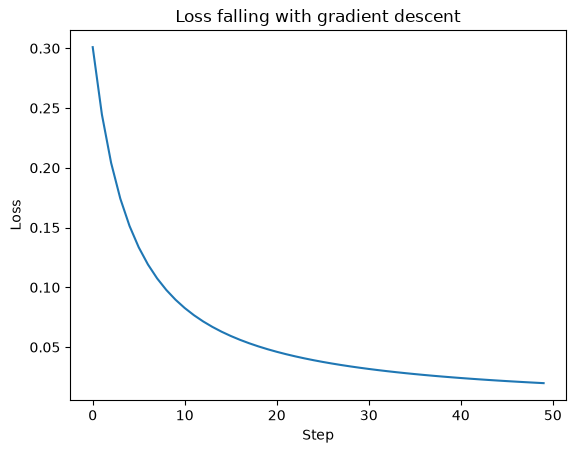

In [5]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('Loss falling with gradient descent');

In [6]:
# ===== Coding a feedforward neural network in TensorFlow =====
# Breast cancer dataset: 30 features, binary target
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

tf.random.set_seed(42)

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

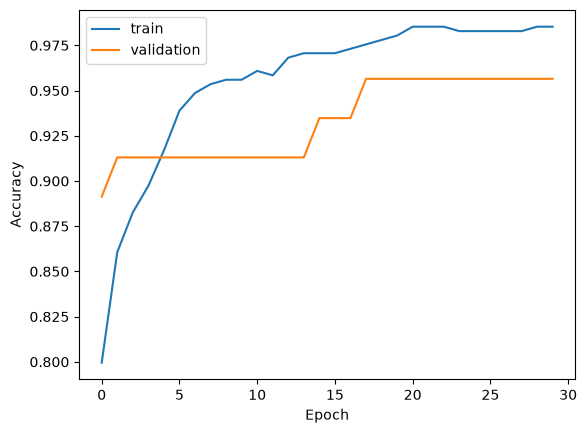

In [8]:
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.1, verbose=0)

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend();

In [9]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", loss)
print("Test accuracy:", accuracy)

Test loss: 0.0661114901304245
Test accuracy: 0.9736841917037964
